# NIH Pneumonia — Larger models & improved training (L4 GPU)
รุ่นปรับปรุงหลังอ่านผล quick_seed42: **ResNet50 pretrained** เป็นโมเดลขนาดใหญ่ขึ้น
เทียบ ResNet18 ภายใต้ split/config เดียวกัน และทดลอง unweighted BCE
มี DenseNet121 เป็นตัวเลือก (ลึกกว่าแต่พารามิเตอร์น้อยกว่า ResNet18)

ค่าเริ่มต้นใช้ **ข้อมูลครบ / official test list** ไม่จำกัด 3,000 ผู้ป่วย
ลด LR, cache ภาพ 224 px ลงดิสก์ local, อ่านข้อมูลหลาย workers, AMP และ checkpoint ใน Drive
ผลจริงต้องรอฝึก ไม่มีการอ้างว่าโมเดลใหญ่จะให้คะแนนดีกว่าแน่นอน
NIH ไม่มี COVID-19: ทำนาย **Pneumonia label present / absent** เท่านั้น
ผลลบอาจมีโรคอื่น ใช้เพื่อการศึกษา

Runtime → Change runtime type → **L4 GPU** (ขึ้นกับสิทธิ์/ทรัพยากรบัญชี)
Run all จะฝึกและสรุป validation แล้วจบ; final test ปิดไว้จนกว่าจะยุติการปรับโมเดล
ถ้าหลุดให้เปิดไฟล์เดิม ตั้ง RESUME=True แล้วรันใหม่ด้วย config/ชื่อเดิมทุกค่า

## 1. เตรียมโค้ดและไลบรารี
เปิด notebook จาก GitHub หรือ upload ไฟล์นี้ได้ โค้ดจะ clone repository เมื่อยังไม่มี `src/`
หากต้องการใช้ commit เดิมให้ใส่ CODE_REF เป็น commit SHA ที่บันทึกไว้
คง torch/torchvision ที่ Colab จัดมาเป็นคู่ไว้ ไม่ติดตั้ง CUDA ทับโดยไม่จำเป็น

In [ ]:
from pathlib import Path
import subprocess, sys, os
REPO = "https://github.com/baconkak/Chest-X-Ray-Pneumonia-COVID-19-Screening.git"
CODE_REF = "main"  # Replace with the saved commit SHA to reproduce this code version.
project = Path("/content/chest-xray-improved")
if not project.exists():
    subprocess.run(["git", "clone", REPO, str(project)], check=True)
os.chdir(project)
subprocess.run(["git", "fetch", "origin", CODE_REF], check=True)
subprocess.run(["git", "checkout", "--detach", "FETCH_HEAD"], check=True)
sys.path.insert(0, str(project))
# A reused runtime may have imported src from the older notebook already.
for module in list(sys.modules):
    if module == "src" or module.startswith("src."):
        del sys.modules[module]
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "scikit-learn>=1.5,<2", "pandas>=2.2,<4", "matplotlib>=3.8,<4",
                "Pillow>=10.4,<13", "kagglehub>=0.3,<1", "tqdm>=4.66,<5"], check=True)
import torch
from src.engine import environment
CODE_SHA = subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()
print(environment())
print("Code commit:", CODE_SHA)

{'python': '3.13.15', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'numpy': '2.1.3', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'device': 'NVIDIA L4'}
Code commit: 37c5073ae17bdf7a3482cccf94c98c618ea73a37


## 2. แผนการทดลองและที่เก็บผล
ค่าเริ่มต้น 3 งาน: ResNet18 weight=10, ResNet50 weight=10 และ ResNet50 weight=1
weight=10 เป็นค่าทดลองเพื่อลดความรุนแรงจากอัตราส่วนประมาณ 112 รอบก่อน ไม่ใช่ค่าที่พิสูจน์ว่าดีที่สุด
weight=1 เท่ากับ BCE ปกติ; ไม่มี oversampling ร่วมด้วย
RUN_EXTRA_ABLATIONS=True เพิ่ม ResNet50 weight=30 และอัตราส่วนจาก train โดยอัตโนมัติ
RUN_DENSENET=True เพิ่ม DenseNet121; แต่ละตัวเพิ่มเวลาฝึก

TRAIN_SEEDS=[42,43,44] ใช้ตรวจความแปรปรวนเมื่อมีเวลา; **SPLIT_SEED คงเดิม**
เลือก family ด้วยค่าเฉลี่ย validation AP และใช้ seed แรกตามแผน ไม่เลือก seed ที่คะแนนดีที่สุด
ต้องเปลี่ยน RUN_NAME ถ้าเปลี่ยนแผน/config; อย่า resume checkpoint รุ่นเก่า
ค่าเริ่มต้นสูงสุด 20 epochs, head 2 แล้ว fine-tune block สุดท้าย; patience 5
epoch แรกจะบอกความเร็วจริงเพื่อประมาณเวลาที่เหลือ งาน full นานกว่า quick อย่างชัดเจน

In [ ]:
from dataclasses import replace
from src.engine import TrainConfig, save_json
USE_DRIVE = True
PROFILE = "full"
RUN_NAME = "nih_full_resnet50_v3"
RESUME = False
SPLIT_SEED = 42
TRAIN_SEEDS = [42]  # Optional: [42, 43, 44], declared before starting a new run.
RUN_EXTRA_ABLATIONS = False
RUN_DENSENET = False
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
OUTPUT_BASE = Path("/content/drive/MyDrive/ChestXrayProject") if USE_DRIVE else Path("outputs")
OUT = OUTPUT_BASE / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)
CFG = TrainConfig(seed=TRAIN_SEEDS[0], epochs=20, head_epochs=2, batch_size=64,
                  lr=1e-4, finetune_lr=1e-5, patience=5, positive_weight=10.,
                  num_workers=4, amp=True, amp_init_scale=1024., progress=True)
SPLIT_MODE = "official" if PROFILE == "full" else "grouped"
MAX_PATIENTS = 3000 if PROFILE == "quick" else None
ALLOW_PARTIAL = False
if PROFILE not in {"full", "quick", "sample"}:
    raise ValueError("PROFILE must be full, quick or sample")
EXPERIMENTS = [
    dict(id="resnet18_pw10", model="resnet18", positive_weight=10.),
    dict(id="resnet50_pw10", model="resnet50", positive_weight=10.),
    dict(id="resnet50_pw1", model="resnet50", positive_weight=1.),
]
if RUN_EXTRA_ABLATIONS:
    EXPERIMENTS += [dict(id="resnet50_pw30", model="resnet50", positive_weight=30.),
                    dict(id="resnet50_pwauto", model="resnet50", positive_weight=None)]
if RUN_DENSENET:
    EXPERIMENTS += [dict(id="densenet121_pw10", model="densenet121", positive_weight=10.)]
print("Output:", OUT)
print("Training jobs:", len(EXPERIMENTS)*len(TRAIN_SEEDS))
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
if not torch.cuda.is_available():
    raise RuntimeError("Choose a GPU runtime before full-data training")

Mounted at /content/drive
Output: /content/drive/MyDrive/ChestXrayProject/nih_full_resnet50_v3
Training jobs: 3
GPU: NVIDIA L4


## 3. ใช้ NIH ชุดเต็มที่มีอยู่ หรือดาวน์โหลด
ข้อมูลเดิมที่แตกครบแล้วยังอยู่ใน runtime จะถูกใช้ต่อ ไม่ต้องดาวน์โหลดซ้ำ
runtime ใหม่ต้องโหลด archive ประมาณ 42 GB และแตกไฟล์ จึงต้องมี free disk อย่างน้อย 110 GiB
ควรใช้ดิสก์รวมประมาณ 210 GB ขึ้นไป และเก็บภาพใน /content ไม่อ่านภาพทีละไฟล์ผ่าน Drive
ไฟล์ต้นฉบับไม่ถูกลบ; cache ภาพเล็กสร้างแยกในขั้นตอนถัดไป
ถ้าเก็บภาพไว้ที่อื่น ตั้ง DOWNLOAD_DATA=False แล้วแก้ DATA_ROOT ให้ถูกต้อง
[แหล่งข้อมูล NIH บน Kaggle](https://www.kaggle.com/datasets/nih-chest-xrays/data)

In [ ]:
import shutil
DOWNLOAD_DATA = True
DATA_ROOT = Path("/content/nih-chestxray14")
KAGGLE_HANDLE = ("nih-chest-xrays/sample/versions/4" if PROFILE == "sample"
                 else "nih-chest-xrays/data/versions/3")
if DOWNLOAD_DATA:
    handle_name, version = ("sample", "4") if PROFILE == "sample" else ("data", "3")
    cached = Path.home()/".cache/kagglehub/datasets/nih-chest-xrays"/handle_name/"versions"/version
    metadata = list(cached.rglob("sample_labels.csv")) + list(cached.rglob("Data_Entry_2017*.csv"))
    if cached.is_dir() and len(metadata) == 1:
        DATA_ROOT = cached
        print("Using existing extracted dataset:", DATA_ROOT)
    else:
        import kagglehub
        free_gib = shutil.disk_usage("/content" if Path("/content").exists() else ".").free/2**30
        required = 10 if PROFILE == "sample" else 110
        print(f"Free disk: {free_gib:.1f} GiB")
        if free_gib < required:
            raise RuntimeError(f"Need at least {required} GiB free for download/extraction")
        DATA_ROOT = Path(kagglehub.dataset_download(KAGGLE_HANDLE))
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(DATA_ROOT)
print("Dataset path:", DATA_ROOT)

Free disk: 193.3 GiB


100%|██████████| 42.0G/42.0G [48:12<00:00, 15.6MB/s]

Extracting files...


Dataset path: /root/.cache/kagglehub/datasets/nih-chest-xrays/data/versions/3


### Data Analyze

In [11]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
from glob import glob
%matplotlib inline
import matplotlib.pyplot as plt

In [13]:
import os
from glob import glob

# Use the DATA_ROOT variable already defined and downloaded in previous steps
metadata_file = DATA_ROOT / 'Data_Entry_2017.csv'

all_xray_df = pd.read_csv(metadata_file)

# Match images globally within the correct DATA_ROOT directory tree
all_image_paths = {os.path.basename(x): x for x in
                   glob(os.path.join(str(DATA_ROOT), 'images*', '*', '*.png'))}

print('Scans found:', len(all_image_paths), ', Total Headers:', all_xray_df.shape[0])
all_xray_df['path'] = all_xray_df['Image Index'].map(all_image_paths.get)
all_xray_df['Patient Age'] = all_xray_df['Patient Age'].map(lambda x: int(str(x)[:-1]) if isinstance(x, str) else int(x))
all_xray_df.sample(3)

Scans found: 112120 , Total Headers: 112120


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11,path
89645,00022260_003.png,No Finding,3,22260,54,F,PA,2542,2434,0.143,0.143,NaN,/root/.cache/kagglehub/datasets/nih-chest-xray...
47446,00012048_007.png,Infiltration|Mass|Nodule,7,12048,65,M,AP,2500,2048,0.168,0.168,NaN,/root/.cache/kagglehub/datasets/nih-chest-xray...
57963,00014352_005.png,No Finding,5,14352,6,M,PA,2992,2033,0.143,0.143,NaN,/root/.cache/kagglehub/datasets/nih-chest-xray...


### Preprocessing Lables

In [15]:
# Extract all unique individual labels by splitting on the '|' character
unique_labels = set()
all_xray_df['Finding Labels'].str.split('|').apply(unique_labels.update)

# Sort and clean
unique_labels = sorted(list(unique_labels))
print(f"Total unique individual classes found: {len(unique_labels)}")
print("List of all classes:")
for label in unique_labels:
    print(f"- {label}")

Total unique individual classes found: 15
List of all classes:
- Atelectasis
- Cardiomegaly
- Consolidation
- Edema
- Effusion
- Emphysema
- Fibrosis
- Hernia
- Infiltration
- Mass
- No Finding
- Nodule
- Pleural_Thickening
- Pneumonia
- Pneumothorax


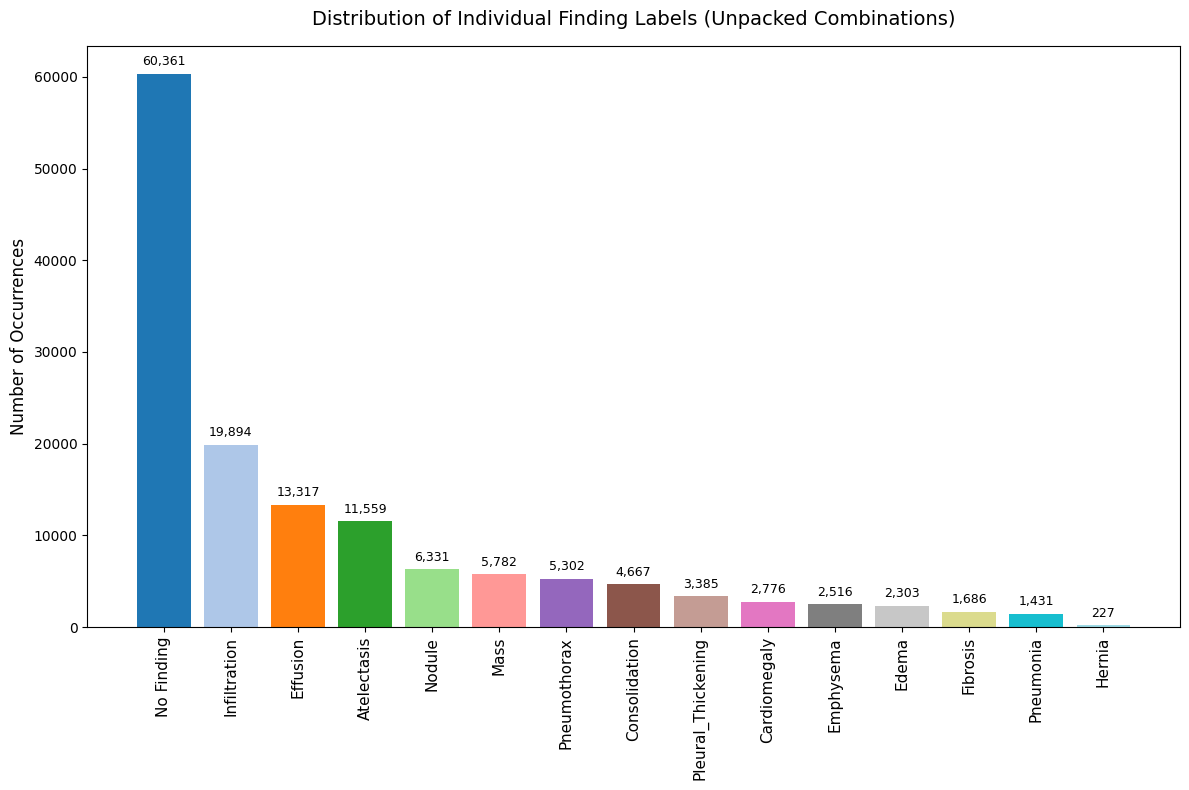

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Flatten all label combinations to count occurrences of each individual disease
all_labels_flat = all_xray_df['Finding Labels'].str.split('|').explode()
individual_label_counts = all_labels_flat.value_counts()

# 2. Plot the individual label distribution
fig, ax1 = plt.subplots(1, 1, figsize=(12, 8))
colors = plt.cm.tab20(np.linspace(0, 1, len(individual_label_counts)))

ax1.bar(np.arange(len(individual_label_counts)) + 0.5, individual_label_counts, color=colors)
ax1.set_xticks(np.arange(len(individual_label_counts)) + 0.5)
ax1.set_xticklabels(individual_label_counts.index, rotation=90, fontsize=11)
ax1.set_title("Distribution of Individual Finding Labels (Unpacked Combinations)", fontsize=14, pad=15)
ax1.set_ylabel("Number of Occurrences", fontsize=12)

# Add exact count values on top of each bar
for i, val in enumerate(individual_label_counts):
    ax1.text(i + 0.5, val + (max(individual_label_counts) * 0.01), f"{val:,}", ha='center', va='bottom', rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

## 4. ตรวจ metadata และแบ่งผู้ป่วยก่อน augmentation
ภาพที่มี `Pneumonia|Effusion` เป็น positive ด้วย ไม่ทิ้งภาพหลายโรค
label ไม่พบ Pneumonia = negative ของ label นี้ ไม่ได้แปลว่าสุขภาพดีหรือไม่มี COVID-19
patient stratum คือมีอย่างน้อยหนึ่งภาพ positive ใช้เพื่อรักษาสัดส่วนผู้ป่วยคร่าว ๆ
จำนวนภาพและ prevalence ไม่จำเป็นต้องเท่ากันทุก split

อ่าน summary แล้วตรวจว่าแต่ละชุดมี positive เพียงพอ หากมีเพียงหลักหน่วยควรเพิ่มข้อมูล
ตรวจไฟล์เสียทั้งหมดก่อนฝึก (ใช้เวลาสักพัก) และตรวจตัวอย่างภาพด้วยตา

In [ ]:
from src.data import read_metadata, make_splits, save_splits
from PIL import Image
import pandas as pd
df, audit = read_metadata(DATA_ROOT, allow_partial=ALLOW_PARTIAL)
if PROFILE == "sample" and audit["metadata_file"] != "sample_labels.csv":
    raise ValueError("PROFILE='sample' requires NIH sample_labels.csv; use a new run for a different dataset")
splits = make_splits(df, DATA_ROOT, mode=SPLIT_MODE, seed=SPLIT_SEED, max_patients=MAX_PATIENTS)
if (OUT / "data_audit.json").exists():
    import json
    old_audit = json.loads((OUT / "data_audit.json").read_text(encoding="utf-8"))
    if not RESUME:
        raise FileExistsError("RUN_NAME already exists: use RESUME=True or a new RUN_NAME")
    if old_audit["audit"]["metadata_sha256"] != audit["metadata_sha256"]:
        raise ValueError("Dataset metadata changed; start a new run")
    for split_name, frame in splits.items():
        old = pd.read_csv(OUT / "splits" / f"{split_name}.csv", dtype={"patient_id":str})
        if list(old["Image Index"]) != list(frame["Image Index"]):
            raise ValueError("Split changed; start a new run")
split_hash, summary = save_splits(splits, OUT / "splits")
save_json(dict(audit=audit, summary=summary, split_hash=split_hash,
               protocol=SPLIT_MODE, profile=PROFILE, max_patients=MAX_PATIENTS,
               code_commit=CODE_SHA, dataset_handle=KAGGLE_HANDLE,
               resolved_dataset_path=str(DATA_ROOT)), OUT / "data_audit.json")
display(pd.DataFrame(summary).T)
for split_name, frame in splits.items():
    for path in frame.path:
        with Image.open(path) as im:
            im.verify()
print("Image integrity and patient overlap checks passed; split hash:", split_hash)

,images,patients,positive_images,prevalence
train,68781.0,22406.0,695.0,0.010105
val,17743.0,5602.0,181.0,0.010201
test,25596.0,2797.0,555.0,0.021683


Image integrity and patient overlap checks passed; split hash: 619130b7549abed4d45a997ab9ac867a323c001764105ad14f6c644d91e25149


## 5. Cache ภาพลง local disk และตรวจภาพ
ย่อแบบ pad + resize เป็น 224×224 **ครั้งเดียว** ก่อน augmentation แล้วบันทึก PNG RGB แบบไม่สูญเสียเพิ่ม
ลดการเปิดและย่อ PNG ต้นฉบับขนาดใหญ่ทุก epoch; ไม่ cache ภาพที่สุ่มหมุน/เลื่อนแล้ว
ชื่อ cache อิง path, ขนาดไฟล์, เวลาแก้ไขและรุ่น preprocessing; ใช้ต่อได้ใน runtime เดิม
เปลี่ยนข้อมูลต้นฉบับให้สร้าง cache ใหม่ (ระบบนี้ไม่ใช้ content hash ของภาพทุกไฟล์)
ขั้นตอนแรกยังใช้เวลา แต่ progress bar แสดงความคืบหน้า
ใช้ 4 workers + pinned memory; ปิด persistent workers เพื่อให้ resume สุ่ม augmentation ต่อได้ที่ขอบ epoch
Batch 64 เป็นค่าเริ่มต้นสำหรับ L4 ที่ 224 px; ถ้า OOM ให้เริ่ม RUN_NAME ใหม่ด้วย batch 32
GPU RAM ไม่จำเป็นต้องเต็ม และต้องดู img/s ร่วมด้วย

Cache resized images:   0%|          | 0/112120 [00:00<?, ?it/s]

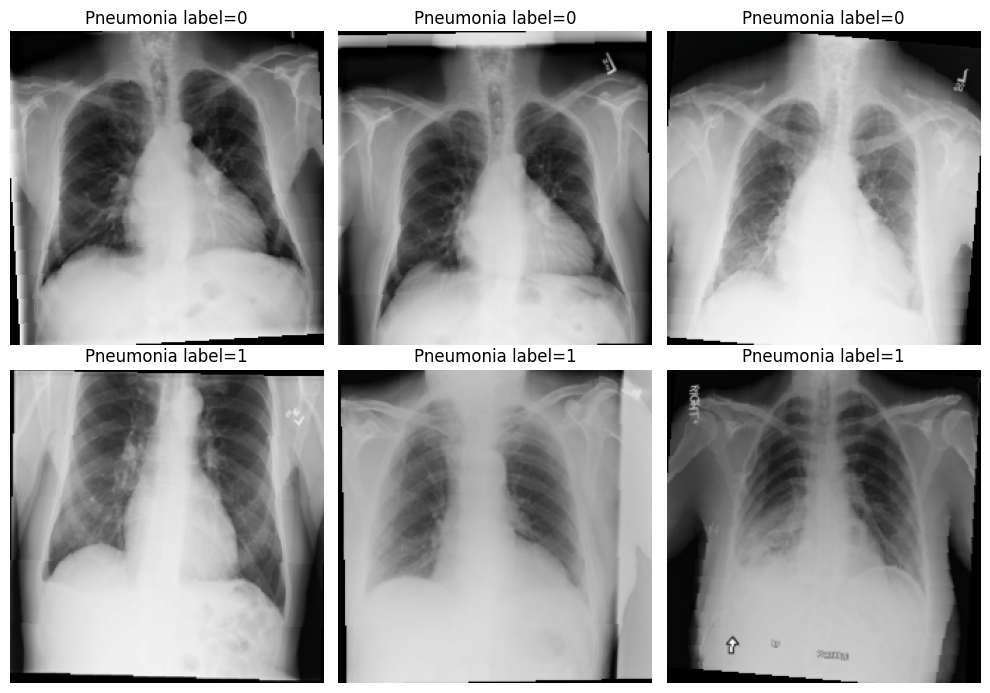

In [ ]:
from src.data import prepare_image_cache
CACHE_IMAGES = True
CACHE_ROOT = Path("/content/nih_cache") if Path("/content").exists() else Path("data/nih_cache")
if CACHE_IMAGES:
    free_gib = shutil.disk_usage("/content" if Path("/content").exists() else ".").free/2**30
    if free_gib < 12:
        raise RuntimeError("Keep at least 12 GiB free for cache/checkpoints or set CACHE_IMAGES=False")
    combined = pd.concat(list(splits.values()), ignore_index=True)
    cached_frame = prepare_image_cache(combined, CACHE_ROOT, CFG.image_size, workers=4)
    paths = cached_frame.set_index("Image Index").path
    splits = {key: frame.assign(path=frame["Image Index"].map(paths)) for key, frame in splits.items()}
    save_json(dict(cache_root=str(CACHE_ROOT), size=CFG.image_size,
                   transform="RGB pad+resize v1; random affine remains online"), OUT/"cache_info.json")

import matplotlib.pyplot as plt
import numpy as np
from src.data import ChestDataset
sample = splits["train"].groupby("target", group_keys=False).head(3)
dataset = ChestDataset(sample, train=True, size=CFG.image_size)
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for i, ax in enumerate(axes.flat):
    if i >= len(dataset):
        ax.axis("off"); continue
    x, y = dataset[i]
    image = x.permute(1,2,0).numpy() * [.229,.224,.225] + [.485,.456,.406]
    ax.imshow(np.clip(image, 0, 1)); ax.set_title(f"Pneumonia label={int(y.item())}"); ax.axis("off")
plt.tight_layout(); plt.show()

## 6. ฝึกและเปรียบเทียบโมเดล
ResNet50 มีประมาณ 23.51 ล้านพารามิเตอร์หลังเปลี่ยนหัวเป็น 1 logit เทียบ ResNet18 ประมาณ 11.18 ล้าน
DenseNet121 ตัวเลือกมีประมาณ 6.95 ล้าน จึงลึกกว่าแต่ไม่ใหญ่กว่าในจำนวนพารามิเตอร์
ทุกโมเดล pretrained จาก ImageNet ไม่ใช่ pretrained สำหรับ COVID หรือ NIH
ฝึกหัวก่อน แล้วเปิด block สุดท้าย; BatchNorm ใช้สถิติ pretrained คงที่
LR หัว=0.0001 / fine-tune=0.00001; ลดลงอีกเมื่อ validation AP ไม่ดีขึ้น
ใช้ BCEWithLogitsLoss เพราะเป็น binary label เดียวและรับ logit โดยตรง; weight เทียบจาก validation
AMP เริ่ม scale=1024, clip norm=5 และตรวจ non-finite; ไม่ oversample พร้อม weighted loss
แสดง progress, img/s, peak GPU memory และเวลาราย epoch ใน history.csv

แต่ละ trial เก็บแยก; seed ของ split ไม่เปลี่ยนตาม seed training
ยังไม่เปิด final test ระหว่างเลือกโมเดลหรือน้ำหนัก loss

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 233MB/s]


resnet18 train:   0%|          | 0/1075 [00:00<?, ?it/s]

resnet18 val:   0%|          | 0/278 [00:00<?, ?it/s]

resnet18 epoch=1 stage=head train=0.3512 val_BCE=0.1093 val_AP=0.0152 train=946.3 img/s peak_GPU=488 MiB


...

resnet18 train:   0%|          | 0/1075 [00:00<?, ?it/s]

/content/chest-xray-improved/src/engine.py:118: UserWarning: AMP gradient overflow: update skipped and loss scale reduced
  warnings.warn('AMP gradient overflow: update skipped and loss scale reduced')


resnet18 val:   0%|          | 0/278 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f81eaf498a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f81eaf498a0>AssertionError
: can only test a child processTraceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

resnet18 epoch=16 stage=finetune train=0.1901 val_BCE=0.0657 val_AP=0.0216 train=1078.1 img/s peak_GPU=585 MiB


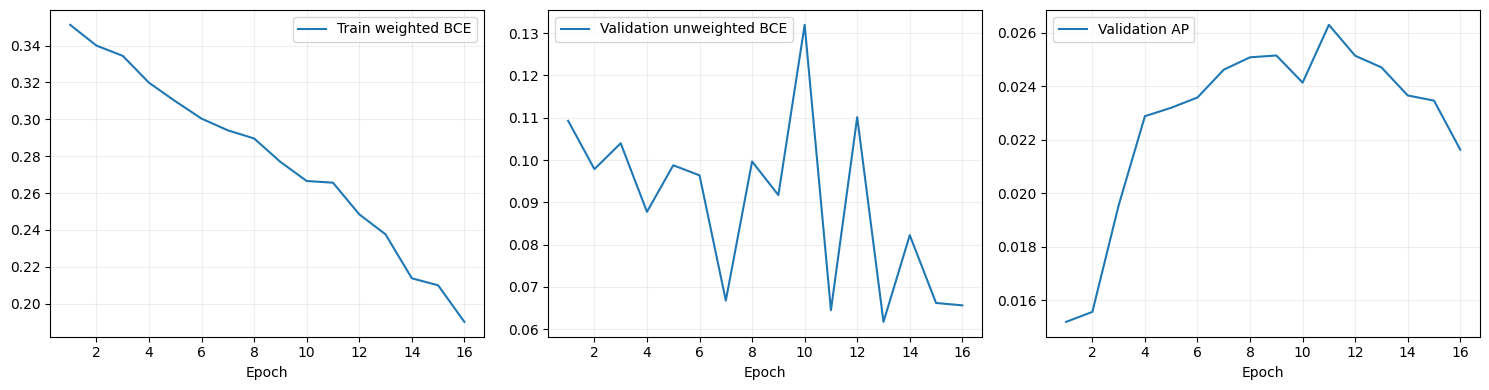

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 125MB/s]


resnet50 train:   0%|          | 0/1075 [00:00<?, ?it/s]

resnet50 val:   0%|          | 0/278 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f81eaf498a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f81eaf498a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

...

resnet50 epoch=10 stage=finetune train=0.2195 val_BCE=0.0848 val_AP=0.0202 train=989.1 img/s peak_GPU=955 MiB


resnet50 train:   0%|          | 0/1075 [00:00<?, ?it/s]

resnet50 val:   0%|          | 0/278 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f81eaf498a0><function _MultiProcessingDataLoaderIter.__del__ at 0x7f81eaf498a0>
Traceback (most recent call last):

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        self._shutdown_workers()self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only te

resnet50 epoch=11 stage=finetune train=0.2001 val_BCE=0.0762 val_AP=0.0178 train=975.6 img/s peak_GPU=955 MiB


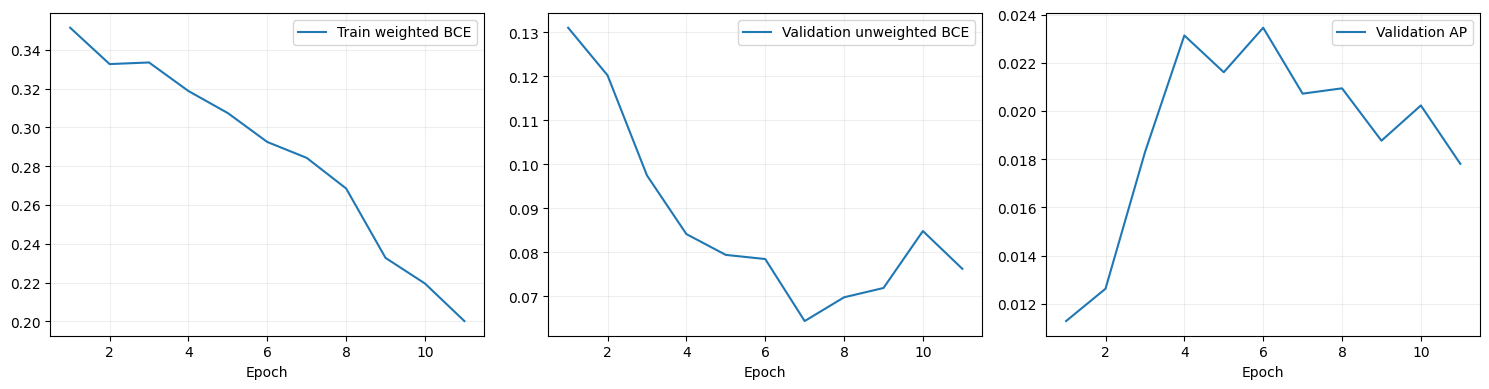

resnet50 train:   0%|          | 0/1075 [00:00<?, ?it/s]

resnet50 val:   0%|          | 0/278 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f81eaf498a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError
: can only test a child processException ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f81eaf498a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

resnet50 epoch=1 stage=head train=0.0920 val_BCE=0.0603 val_AP=0.0096 train=1099.1 img/s peak_GPU=781 MiB


resnet50 train:   0%|          | 0/1075 [00:00<?, ?it/s]

...

resnet50 epoch=8 stage=finetune train=0.0442 val_BCE=0.0589 val_AP=0.0209 train=987.5 img/s peak_GPU=955 MiB


resnet50 train:   0%|          | 0/1075 [00:00<?, ?it/s]

resnet50 val:   0%|          | 0/278 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f81eaf498a0>
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f81eaf498a0>Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():

Exception ignored in:   File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'<function _MultiProcessingDataLoaderIter.__del__ at 0x7f81eaf498a0>

Traceback (most recent call last):
AssertionError  File "/usr/local/lib/python3.13/dist-packages/torch/util

resnet50 epoch=9 stage=finetune train=0.0397 val_BCE=0.0661 val_AP=0.0185 train=986.9 img/s peak_GPU=955 MiB


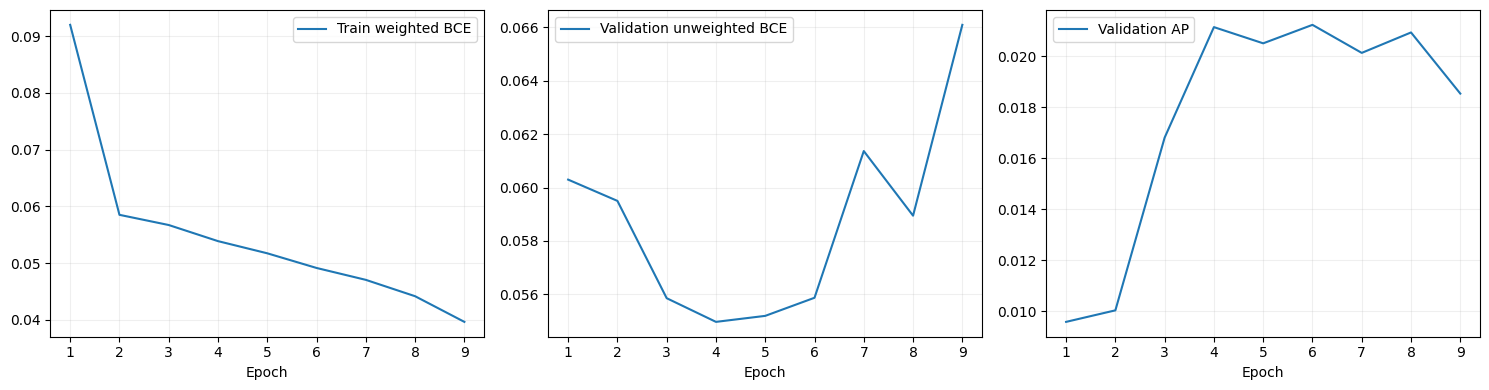

,experiment,trial,seed,model,n,positives,prevalence,threshold,tn,fp,fn,tp,accuracy,precision,recall,specificity,f1,ap,auroc,brier
0,resnet18_pw10,resnet18_pw10_seed42,42,resnet18,17743,181,0.010201,0.002323,5101,12461,18,163,0.296680,0.012912,0.900552,0.290457,0.025459,0.026287,0.702774,0.012182
1,resnet50_pw10,resnet50_pw10_seed42,42,resnet50,17743,181,0.010201,0.008030,4882,12680,18,163,0.284337,0.012692,0.900552,0.277987,0.025031,0.023454,0.684595,0.014584
2,resnet50_pw1,resnet50_pw1_seed42,42,resnet50,17743,181,0.010201,0.003535,5281,12281,18,163,0.306825,0.013099,0.900552,0.300706,0.025822,0.021137,0.695878,0.010055


,experiment,mean_ap,std_ap,seeds,mean_auroc
0,resnet18_pw10,0.026287,NaN,1,0.702774
1,resnet50_pw10,0.023454,NaN,1,0.684595
2,resnet50_pw1,0.021137,NaN,1,0.695878


,trial,rule,n,positives,prevalence,threshold,tn,fp,fn,tp,accuracy,precision,recall,specificity,f1,ap,auroc,brier
0,resnet18_pw10_seed42,validation_recall>=0.5,17743,181,0.010201,0.027604,13889,3673,90,91,0.787916,0.024176,0.502762,0.790855,0.046134,0.026287,0.702774,0.012182
1,resnet18_pw10_seed42,validation_recall>=0.8,17743,181,0.010201,0.004783,7715,9847,36,145,0.442992,0.014512,0.801105,0.439301,0.028507,0.026287,0.702774,0.012182
2,resnet18_pw10_seed42,validation_recall>=0.9,17743,181,0.010201,0.002323,5101,12461,18,163,0.296680,0.012912,0.900552,0.290457,0.025459,0.026287,0.702774,0.012182
3,resnet18_pw10_seed42,fixed_threshold_0.5,17743,181,0.010201,0.500000,17550,12,181,0,0.989122,0.000000,0.000000,0.999317,0.000000,0.026287,0.702774,0.012182
4,resnet50_pw10_seed42,validation_recall>=0.5,17743,181,0.010201,0.050169,13266,4296,84,97,0.753142,0.022081,0.535912,0.755381,0.042414,0.023454,0.684595,0.014584
5,resnet50_pw10_seed42,validation_recall>=0.8,17743,181,0.010201,0.014945,7827,9735,36,145,0.449304,0.014676,0.801105,0.445678,0.028824,0.023454,0.684595,0.014584
6,resnet50_pw10_seed42,validation_recall>=0.9,17743,181,0.010201,0.008030,4882,12680,18,163,0.284337,0.012692,0.900552,0.277987,0.025031,0.023454,0.684595,0.014584
7,resnet50_pw10_seed42,fixed_threshold_0.5,17743,181,0.010201,0.500000,17552,10,180,1,0.989292,0.090909,0.005525,0.999431,0.010417,0.023454,0.684595,0.014584
8,resnet50_pw1_seed42,validation_recall>=0.5,17743,181,0.010201,0.011443,13669,3893,90,91,0.775517,0.022841,0.502762,0.778328,0.043697,0.021137,0.695878,0.010055
9,resnet50_pw1_seed42,validation_recall>=0.8,17743,181,0.010201,0.005556,8568,8994,34,147,0.491180,0.016081,0.812155,0.487872,0.031538,0.021137,0.695878,0.010055


In [ ]:
from src.engine import train_model, load_trained
from src.experiments import run_experiments, lock_selection
validation_table, seed_summary = run_experiments(
    splits, CFG, EXPERIMENTS, TRAIN_SEEDS, split_hash, OUT, resume=RESUME)
display(validation_table)
display(seed_summary)
display(pd.read_csv(OUT/"validation_operating_points.csv"))

## 7. ล็อกตัวเลือกจาก validation
เลือก experiment ด้วย mean AP ของ seeds ตามแผน; ถ้าเสมอใช้ลำดับที่ประกาศ
ใช้ checkpoint ของ seed แรกเสมอ ไม่เลือก seed ที่ได้คะแนนดีที่สุด
threshold หลัก: precision สูงสุดภายใต้ validation recall ≥ 0.90 เช่นเดิม
ตาราง operating points แสดง recall เป้าหมาย 0.50/0.80/0.90 และ threshold 0.5 เพื่อดู false positives
ตารางนี้เป็นการวิเคราะห์ validation; ไม่เปลี่ยนเกณฑ์หลักอัตโนมัติหลังเห็นผล
ถ้าอยากปรับเกณฑ์ ต้องตัดสินใจก่อนเปิด test และบันทึกแผนใหม่ให้ชัดเจน

In [ ]:
selection = lock_selection(validation_table, seed_summary, TRAIN_SEEDS, split_hash, OUT)
winner = selection["selected_trial"]
save_json(dict(training_code_commit=CODE_SHA), OUT/"code_version.json")
print("Selected experiment:", selection["selected_experiment"])
print("Checkpoint:", OUT/winner/selection["selected_model"]/"best.pt")
print("Validation summary:", OUT/"validation_comparison.csv")

Selected experiment: resnet18_pw10
Checkpoint: /content/drive/MyDrive/ChestXrayProject/nih_full_resnet50_v3/resnet18_pw10_seed42/resnet18/best.pt
Validation summary: /content/drive/MyDrive/ChestXrayProject/nih_full_resnet50_v3/validation_comparison.csv


## 8. Final test — รันหลังปิดการปรับโมเดลเท่านั้น
ตั้ง RUN_FINAL_TEST=True เมื่อยอมรับ protocol/config แล้ว ผลทดสอบใช้เพื่อรายงานครั้งสุดท้าย
ถ้าเปลี่ยนโมเดลจากผล test ชุดนี้จะกลายเป็น development data ต้องมี holdout ใหม่
รายงานทุกโมเดลตามแผนที่กำหนด รวม majority baseline ไม่เลือกผู้ชนะใหม่จาก test
bootstrap สุ่มทั้งผู้ป่วย 200 ครั้ง เพื่อประมาณ finite-sample uncertainty ของ image-level AP
ไม่ใช่ความไม่แน่นอนรายบุคคลหรือความแปรปรวนจากการฝึกหลาย seeds

In [ ]:
RUN_FINAL_TEST = False  # Freeze development before setting True.
if RUN_FINAL_TEST:
    from src.data import make_loaders
    from src.engine import predict
    from src.metrics import binary_metrics, patient_bootstrap_ap
    from src.plots import evaluation_plot
    test_dir = OUT/"final_test"
    if (test_dir/"STARTED.json").exists():
        raise RuntimeError("Test was already opened. Read saved artifacts; do not tune on test.")
    test_dir.mkdir(exist_ok=True)
    save_json(dict(selection=selection, code_commit=CODE_SHA), test_dir/"STARTED.json")
    loaders, _ = make_loaders(splits, CFG.batch_size, SPLIT_SEED, CFG.image_size, CFG.num_workers)
    test_frame = splits["test"]
    rows = []
    predictions = test_frame[["Image Index", "patient_id", "target"]].copy()
    for trial in selection["trials"]:
        trial_id, name = trial["trial"], trial["model"]
        model, _ = load_trained(OUT/trial_id/name/"best.pt", "cuda" if torch.cuda.is_available() else "cpu")
        y, scores = predict(model, loaders["test"], next(model.parameters()).device)
        metrics = binary_metrics(y, scores, selection["thresholds"][trial_id])
        predictions[trial_id] = scores
        boot = test_frame[["patient_id", "target"]].copy(); boot["score"] = scores
        ci = patient_bootstrap_ap(boot, repeats=1000)
        rows.append(dict(trial=trial_id, model=name, **metrics, ap_ci_low=ci["low"], ap_ci_high=ci["high"]))
        evaluation_plot(y, scores, metrics, test_dir/f"{trial_id}_evaluation.png")
        errors = test_frame.drop(columns="path").copy()
        errors["score"] = scores; errors["prediction"] = (scores >= metrics["threshold"]).astype(int)
        errors["error"] = np.select([(errors.target==1)&(errors.prediction==0),
                                     (errors.target==0)&(errors.prediction==1)], ["FN","FP"], default="correct")
        errors.to_csv(test_dir/f"{trial_id}_errors.csv", index=False)
        del model
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    prevalence = float(splits["train"].target.mean())
    rows.append(dict(trial="train_prevalence_baseline", model="baseline",
                     **binary_metrics(y, np.full(len(y), prevalence), .5)))
    predictions.to_csv(test_dir/"all_predictions.csv", index=False)
    results = pd.DataFrame(rows); results.to_csv(test_dir/"test_comparison.csv", index=False)
    reference = f"resnet18_pw10_seed{TRAIN_SEEDS[0]}"
    delta = patient_bootstrap_ap(predictions, score_a=reference, score_b=winner, repeats=1000)
    save_json(dict(comparison=f"{winner} minus {reference} AP", paired_patient_bootstrap=delta),
              test_dir/"paired_ap_delta.json")
    display(results)
else:
    print("Training/validation completed. Final test is still unopened.")

Training/validation completed. Final test is still unopened.


## 9. ลองภาพเดี่ยวด้วยโมเดลที่เลือก และ Grad-CAM
ภาพ PNG/JPEG; ไม่ใช่ DICOM และไม่ใช่ตัววินิจฉัย
Grad-CAM ใช้ block สุดท้ายของ ResNet หรือ DenseNet และไม่ได้ยืนยันตำแหน่งรอยโรค
score จาก weighted BCE ยังไม่ใช่ probability ทางคลินิกที่ผ่าน calibration

In [ ]:
IMAGE_PATH = ""  # Set an image path to run the example. No image is uploaded anywhere.
if IMAGE_PATH:
    from src.data import transforms
    from src.explain import grad_cam
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, _ = load_trained(OUT / winner / selection["selected_model"] / "best.pt", device)
    with Image.open(IMAGE_PATH) as image:
        x = transforms(size=CFG.image_size)(image.convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        score = float(model(x).sigmoid().item())
    threshold = selection["thresholds"][winner]
    print({"pneumonia_label_score": score, "threshold": threshold,
           "flag_for_educational_review": score >= threshold, "covid19": "not supported"})
    cam = grad_cam(model, x)[0]
    rgb = x[0].detach().cpu().permute(1,2,0).numpy() * [.229,.224,.225] + [.485,.456,.406]
    plt.imshow(np.clip(rgb,0,1)); plt.imshow(cam, cmap="jet", alpha=.4)
    plt.axis("off"); plt.title("Positive-logit Grad-CAM (not a diagnosis)"); plt.show()

## 10. ผลลัพธ์และการฝึกต่อ
Drive → MyDrive → ChestXrayProject → nih_full_resnet50_v3
ดู validation_comparison.csv, validation_seed_summary.csv, validation_operating_points.csv
แต่ละ trial มี run.json, history.csv, learning_curves.png, best.pt, last.pt และ val_predictions.csv
locked_selection.json บอกโมเดล/threshold ที่เลือก; final_test สร้างเมื่อเปิด test เท่านั้น
std_ap ว่างเมื่อมี seed เดียว เป็นค่าที่คำนวณไม่ได้ ไม่ใช่ความแปรปรวนศูนย์
save checkpoints ทุกขอบ epoch; หลุดกลาง epoch จะเริ่ม epoch นั้นใหม่
config ต้องตรงเดิม; เปลี่ยนโมเดล/batch/loss/seeds ต้องเริ่ม RUN_NAME ใหม่
อย่าเทียบ AP ตรงกับ quick รอบก่อน เพราะชุดผู้ป่วย/validation ต่างกัน ให้เทียบ baseline รอบ full เดียวกัน
ผลดีขึ้นหรือไม่ต้องพิจารณา AP, false positives, patient bootstrap และความแปรปรวนข้าม seeds ร่วมกัน
อ่านเหตุผลฉบับละเอียดใน README.md หัวข้อรุ่นปรับปรุง

อ้างอิง: [ResNet50](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html),
[DenseNet121](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.densenet121.html),
[PyTorch DataLoader](https://docs.pytorch.org/docs/stable/data.html),
[BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html)

In [ ]:
(OUT / "environment_freeze.txt").write_text(
    subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True), encoding="utf-8")
print("Artifacts saved in:", OUT)
print("Use the result files to complete the report; do not report smoke-test scores as real performance.")

Artifacts saved in: /content/drive/MyDrive/ChestXrayProject/nih_full_resnet50_v3
Use the result files to complete the report; do not report smoke-test scores as real performance.
